In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import cdist

df = pd.read_csv("Iris.csv")
print(df.head())
print("Dataset shape:", df.shape)

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Dataset shape: (150, 6)


In [2]:
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X = df[features]

scaler = StandardScaler()
X = scaler.fit_transform(X)

#### Elbow Method for Optimal K


C:\Users\ramme\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ramme\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ramme\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ramme\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

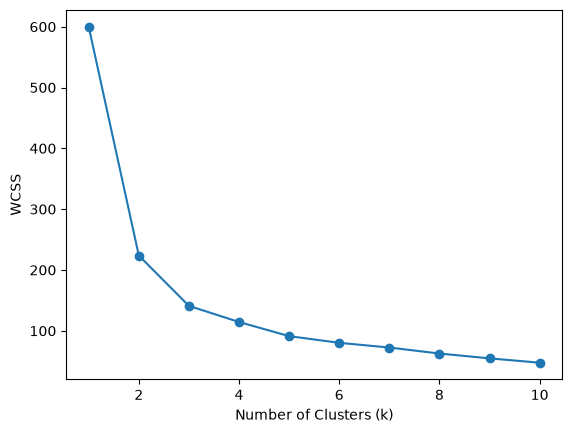

In [3]:
wcss = []
for k in range(1, 11):
  kmeans = KMeans(n_clusters=k, n_init=10).fit(X)
  wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.show()


**Observation:** For the Iris dataset, K = 3 is a reasonable choice. The elbow may not be perfectly sharp.

#### K-Means Clustering Algorithm

K-Means cluster sizes:
KMeans
0    53
1    50
2    47
Name: count, dtype: int64


C:\Users\ramme\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


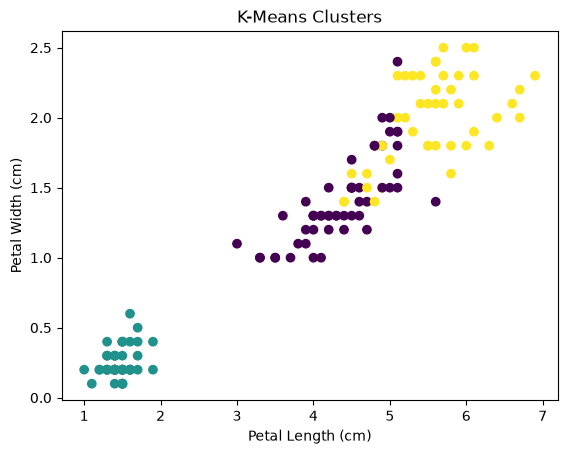

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["KMeans"] = kmeans.fit_predict(X)

print("K-Means cluster sizes:")
print(df["KMeans"].value_counts().sort_index())

plt.scatter(df["PetalLengthCm"], df["PetalWidthCm"], c=df["KMeans"], cmap="viridis")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("K-Means Clusters")
plt.show()

#### 2. Hierarchical Clustering Algorithm

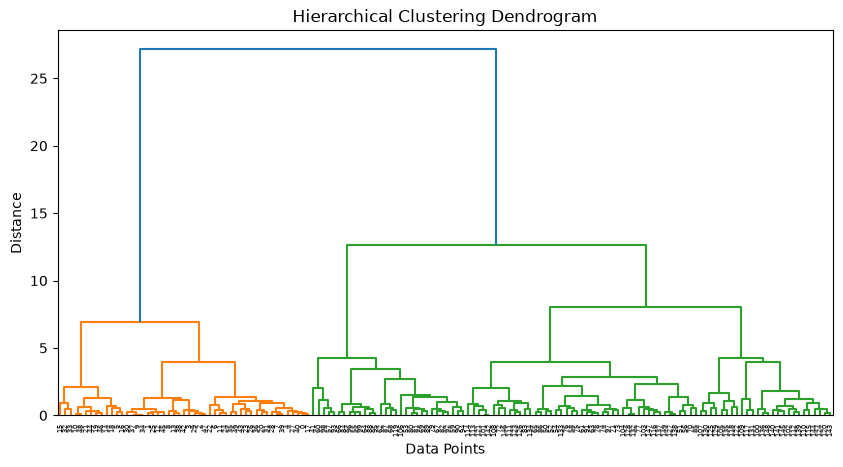

In [5]:
Z = linkage(X, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()


#### Applying Clustering - Agglomerative

In [6]:
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

df["Hierarchical"] = hc.fit_predict(X)

print("Hierarchical Cluster Sizes:")
print(df["Hierarchical"].value_counts().sort_index())

Hierarchical Cluster Sizes:
Hierarchical
0    71
1    49
2    30
Name: count, dtype: int64


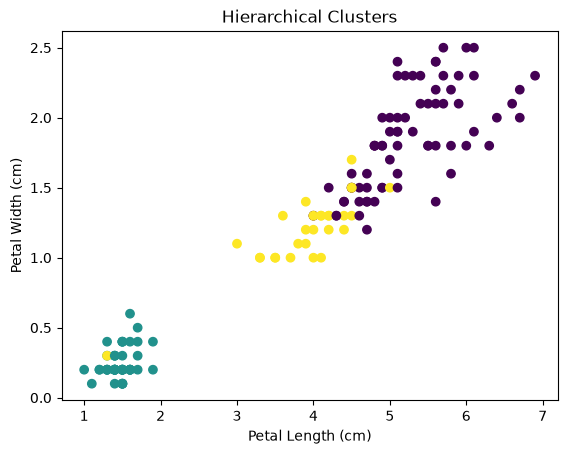

In [7]:
plt.scatter(
    df["PetalLengthCm"],
    df["PetalWidthCm"],
    c=df["Hierarchical"],
    cmap="viridis"
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Hierarchical Clusters")
plt.show()

In [11]:
# Dunn index = min inter-cluster distance / max intra-cluster distance
def dunn(X, labels):
    clusters = [X[labels == c] for c in np.unique(labels)]
    min_distance = min(cdist(a, b).min() for i, a in enumerate(clusters) for b in clusters[i+1:])
    max_distance = max(cdist(a, a).max() for a in clusters)
    return min_distance / max_distance

print("--- Evaluation & Comparison ---")
print("K-Means Dunn Index:", round(dunn(X, df["KMeans"]), 4))
print("Hierarchical Dunn Index:", round(dunn(X, df["Hierarchical"]), 4))

--- Evaluation & Comparison ---
K-Means Dunn Index: 0.0264
Hierarchical Dunn Index: 0.098
